# Tempo de tela, duração do sono e estresse em perfis estudantis simulados

**Autor:** Murillo Preto Cardoso Junior  
**Disciplina:** Programação e Ciência de Dados em Saúde

## Apresentação e justificativa

O sono faz parte da rotina de quem estuda, assim como o tempo dedicado às atividades acadêmicas, ao lazer e ao uso de telas. Essa convivência desperta uma pergunta: quando comparamos perfis com diferentes tempos de tela, que diferenças encontramos nas horas de sono? Outra questão surge quando olhamos para o estresse. Quando agrupamos os perfis pela duração média do sono, quais escores de estresse aparecem com maior frequência em cada faixa e até que ponto essas distribuições se sobrepõem? Essas perguntas orientam a escolha do tema e ajudam a definir o que observar nos dados.

Para explorar essas questões, foi escolhida a base *Student Sleep, Screen Time & Mental Health 2026*, disponibilizada no Kaggle sob licença CC0. O arquivo reúne 3.000 perfis estudantis simulados e 15 variáveis relacionadas às características dos perfis, aos hábitos cotidianos, ao bem-estar e ao desempenho acadêmico. Segundo o autor, os dados foram gerados para fins educacionais, com relações estatísticas planejadas entre algumas variáveis. Cada linha representa, portanto, um perfil fictício.

A escolha dessa base se justifica porque ela reúne, para cada perfil, as três informações necessárias à investigação: o tempo de tela, a duração média do sono e o escore de estresse. Como o tempo de tela e a duração do sono são expressos em horas, podemos representá-los em um gráfico no qual cada ponto corresponde a um perfil. Isso permite observar tanto a tendência geral quanto as diferenças entre perfis com tempos de tela semelhantes. Já o escore de estresse permite outra comparação: ao organizar os perfis por faixas de duração do sono, podemos observar quais pontuações são mais frequentes em cada faixa e quais aparecem em várias delas.

Como parte das relações foi planejada durante a geração dos dados, a contribuição deste trabalho está em investigar como essas relações se manifestam no arquivo: qual é a sua intensidade, quanta variação existe entre os perfis e até onde os resultados permitem chegar. Assim, as conclusões descreverão os padrões encontrados na simulação. A possibilidade de que padrões semelhantes ocorram entre estudantes reais exigiria uma investigação com dados coletados nessa população.

## Objetivo geral

Analisar a associação entre o tempo de tela e a duração média do sono nos perfis estudantis simulados e comparar a distribuição dos escores de estresse entre perfis com diferentes durações de sono.

## Perguntas de investigação

1. Qual é a direção e a intensidade da associação entre o tempo de tela e a duração média do sono nos perfis simulados?
2. Como os escores de estresse se distribuem nas diferentes faixas de duração média do sono e em que medida essas distribuições se sobrepõem?

## Fonte dos dados

Kaggle. [Student Sleep, Screen Time & Mental Health 2026](https://www.kaggle.com/datasets/uditjain13/student-sleep-screen-time-and-mental-health-2026). Arquivo utilizado: `student_sleep_mental_health_2026.csv`. Licença CC0.

## 2. Carregamento e reconhecimento da base de dados

Antes de investigar a relação entre tempo de tela, sono e estresse, precisamos entender o que representa cada linha do arquivo e como as informações estão distribuídas nas colunas. Nesta base, cada linha corresponde a um perfil estudantil simulado. Ao ler uma linha, encontramos tanto características desse perfil, como idade e escolaridade, quanto as medidas que utilizaremos nas análises, como horas de tela e duração média do sono.

Para carregar e organizar os dados, utilizaremos a biblioteca `pandas`, que permite trabalhar com o conteúdo do CSV em uma tabela chamada `DataFrame`. Nas etapas de análise, utilizaremos o `matplotlib.pyplot` para construir os gráficos e a função `spearmanr`, da biblioteca `scipy`, para avaliar a direção e a intensidade das associações entre as variáveis.

A leitura inicial será feita com os nomes originais do arquivo. Em seguida, vamos traduzir as 15 colunas para o português. Essa escolha facilita a leitura do código e permite usar a mesma terminologia no dicionário de dados, nos gráficos e na discussão dos resultados.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr

arquivo = "student_sleep_mental_health_2026.csv"
dados_originais = pd.read_csv(arquivo)

dados_originais.head()

,student_id,age,gender,education_level,avg_sleep_hours,screen_time_hours,social_media_hours,study_hours_per_day,exercise_hours_per_week,caffeine_drinks_per_day,stress_level,anxiety_score,gpa,uses_sleep_app,feels_burned_out
0,1,21,Non-binary,High School,8.0,4.9,3.7,5.0,4.8,1,7,7,3.35,False,True
1,2,19,Female,Undergraduate,7.3,7.7,5.3,2.8,4.2,1,8,8,2.81,True,True
2,3,19,Male,Undergraduate,6.1,7.3,3.6,3.6,5.8,1,8,10,3.01,True,True
3,4,16,Male,High School,6.2,7.4,4.0,0.4,2.0,4,9,10,2.76,False,True
4,5,20,Male,Graduate,5.6,12.5,8.3,2.6,6.2,3,10,10,2.67,False,True


In [3]:
numero_perfis, numero_colunas = dados_originais.shape

print(f"Quantidade de perfis simulados: {numero_perfis}")
print(f"Quantidade de colunas: {numero_colunas}")

print("\nColunas presentes no CSV:")
for posicao, nome in enumerate(dados_originais.columns, start=1):
    print(f"{posicao:2d}. {nome}")

Quantidade de perfis simulados: 3000
Quantidade de colunas: 15

Colunas presentes no CSV:
 1. student_id
 2. age
 3. gender
 4. education_level
 5. avg_sleep_hours
 6. screen_time_hours
 7. social_media_hours
 8. study_hours_per_day
 9. exercise_hours_per_week
10. caffeine_drinks_per_day
11. stress_level
12. anxiety_score
13. gpa
14. uses_sleep_app
15. feels_burned_out


### 2.1 Dicionário das variáveis

O quadro apresenta o nome de cada coluna no CSV, o nome adotado no notebook e o significado da informação registrada. Nas medidas de tempo, os nomes em português indicam a unidade e, quando o arquivo especifica, o período de referência. Essa distinção é importante porque, por exemplo, o tempo de estudo é diário e o tempo de exercício é semanal.

| Nome original no CSV | Nome adotado no notebook | Significado e unidade |
|---|---|---|
| `student_id` | `id_perfil` | Código que identifica cada perfil estudantil simulado. |
| `age` | `idade_anos` | Idade atribuída ao perfil, em anos. |
| `gender` | `genero` | Categoria de gênero registrada para o perfil. |
| `education_level` | `nivel_escolaridade` | Nível de escolaridade atribuído ao perfil. |
| `avg_sleep_hours` | `duracao_media_sono_horas` | Duração média do sono, em horas. |
| `screen_time_hours` | `tempo_tela_horas` | Tempo de uso de telas, em horas. |
| `social_media_hours` | `tempo_redes_sociais_horas` | Tempo de uso de redes sociais, em horas. |
| `study_hours_per_day` | `horas_estudo_por_dia` | Tempo de estudo, em horas por dia. |
| `exercise_hours_per_week` | `horas_exercicio_por_semana` | Tempo de exercício físico, em horas por semana. |
| `caffeine_drinks_per_day` | `bebidas_com_cafeina_por_dia` | Quantidade de bebidas com cafeína consumidas por dia. |
| `stress_level` | `nivel_estresse` | Escore de estresse atribuído ao perfil, com valores observados de 1 a 10. |
| `anxiety_score` | `escore_ansiedade` | Escore de ansiedade atribuído ao perfil, com valores observados de 1 a 10. |
| `gpa` | `media_academica_gpa` | Pontuação de desempenho acadêmico expressa na escala GPA. |
| `uses_sleep_app` | `usa_aplicativo_sono` | Indica se o perfil utiliza aplicativo de sono (`True` ou `False`). |
| `feels_burned_out` | `sensacao_esgotamento` | Indica a presença de sensação de esgotamento no perfil (`True` ou `False`). |

In [4]:
nomes_em_portugues = {
    "student_id": "id_perfil",
    "age": "idade_anos",
    "gender": "genero",
    "education_level": "nivel_escolaridade",
    "avg_sleep_hours": "duracao_media_sono_horas",
    "screen_time_hours": "tempo_tela_horas",
    "social_media_hours": "tempo_redes_sociais_horas",
    "study_hours_per_day": "horas_estudo_por_dia",
    "exercise_hours_per_week": "horas_exercicio_por_semana",
    "caffeine_drinks_per_day": "bebidas_com_cafeina_por_dia",
    "stress_level": "nivel_estresse",
    "anxiety_score": "escore_ansiedade",
    "gpa": "media_academica_gpa",
    "uses_sleep_app": "usa_aplicativo_sono",
    "feels_burned_out": "sensacao_esgotamento"
}

# Cria a tabela de trabalho que será utilizada nas próximas etapas.
dados = dados_originais.rename(columns=nomes_em_portugues, errors="raise")

# Visualiza lado a lado as medidas utilizadas nas perguntas do projeto.
colunas_de_interesse = [
    "id_perfil",
    "tempo_tela_horas",
    "duracao_media_sono_horas",
    "nivel_estresse"
]

dados[colunas_de_interesse].head()

,id_perfil,tempo_tela_horas,duracao_media_sono_horas,nivel_estresse
0,1,4.9,8.0,7
1,2,7.7,7.3,8
2,3,7.3,6.1,8
3,4,7.4,6.2,9
4,5,12.5,5.6,10


### 2.2 Síntese da leitura inicial

A leitura do arquivo identificou 3.000 perfis estudantis simulados e 15 colunas. A tradução dos nomes facilitou a localização das três medidas centrais do projeto: tempo de tela, duração média do sono e nível de estresse.

O perfil de identificador 1, por exemplo, apresenta 4,9 horas de tela, duração média do sono de 8,0 horas e escore de estresse igual a 7. Esse exemplo ajuda a compreender o que representa uma linha da tabela. Para investigar se existe uma tendência entre essas medidas, será necessário comparar os perfis e observar a variação presente no conjunto.

Na próxima etapa, examinaremos os tipos de dados, os valores ausentes, as possíveis duplicatas e a coerência dos registros. Essa avaliação permitirá justificar as decisões de preparação antes da construção dos gráficos.

## 3. Avaliação da qualidade e preparação dos dados

Antes de investigar como o tempo de tela, o sono e o estresse se relacionam, precisamos conhecer as condições dos registros que serão utilizados. Vamos verificar se há informações ausentes, se algum perfil aparece mais de uma vez e se os valores são coerentes com as características que representam.

Uma das verificações envolve o tempo de uso de telas e o tempo dedicado às redes sociais. Ao considerar que as duas medidas se referem ao mesmo período, esperamos que o tempo de redes sociais seja menor ou igual ao tempo total de tela. Comparar essas informações dentro de cada perfil permite identificar situações que passariam despercebidas se examinássemos cada coluna separadamente.

Ao final desta etapa, vamos descrever a distribuição das horas de tela, da duração média do sono e dos escores de estresse. Essa primeira leitura servirá de referência para interpretar os gráficos e as comparações entre os perfis.

In [19]:
diagnostico = pd.DataFrame({
    "tipo_no_pandas": dados.dtypes.astype(str),
    "valores_preenchidos": dados.notna().sum(),
    "valores_ausentes": dados.isna().sum(),
    "percentual_ausente": dados.isna().mean().mul(100).round(2)
})

diagnostico

,tipo_no_pandas,valores_preenchidos,valores_ausentes,percentual_ausente
id_perfil,int64,3000,0,0.0
idade_anos,int64,3000,0,0.0
genero,object,3000,0,0.0
nivel_escolaridade,object,3000,0,0.0
duracao_media_sono_horas,float64,3000,0,0.0
tempo_tela_horas,float64,3000,0,0.0
tempo_redes_sociais_horas,float64,3000,0,0.0
horas_estudo_por_dia,float64,3000,0,0.0
horas_exercicio_por_semana,float64,3000,0,0.0
bebidas_com_cafeina_por_dia,int64,3000,0,0.0


In [20]:
caracteristicas = dados.drop(columns="id_perfil")

print("Identificadores distintos:", dados["id_perfil"].nunique())
print("Repetições de identificador:", dados["id_perfil"].duplicated().sum())
print("Linhas inteiramente repetidas:", dados.duplicated().sum())
print("Repetições nas características dos perfis:", caracteristicas.duplicated().sum())

Identificadores distintos: 3000
Repetições de identificador: 0
Linhas inteiramente repetidas: 0
Repetições nas características dos perfis: 0


In [25]:
verificacoes = pd.Series({
    "Tempo de tela fora de 0 a 24 horas":
        (~dados["tempo_tela_horas"].between(0, 24)).sum(),

    "Duração média do sono fora de 0 a 24 horas":
        (~dados["duracao_media_sono_horas"].between(0, 24)).sum(),

    "Tempo negativo de uso de redes sociais":
        (dados["tempo_redes_sociais_horas"] < 0).sum(),

    "Tempo de redes sociais superior ao tempo de tela":
        (dados["tempo_redes_sociais_horas"] > dados["tempo_tela_horas"]).sum()
}, name="quantidade_de_perfis")

display(verificacoes.to_frame())

,quantidade_de_perfis
Tempo de tela fora de 0 a 24 horas,0
Duração média do sono fora de 0 a 24 horas,0
Tempo negativo de uso de redes sociais,0
Tempo de redes sociais superior ao tempo de tela,42


In [31]:
# Recupera do CSV a medida original de cada perfil.
tempo_redes_original = dados_originais["social_media_hours"]

# Gera um indicador por perfil: True quando o tempo de redes supera o de tela.
redes_acima_da_tela = tempo_redes_original > dados["tempo_tela_horas"]

# Exibe exemplos antes de aplicar a regra de preparação.
exemplos = pd.DataFrame({
    "id_perfil": dados["id_perfil"],
    "tempo_tela_horas": dados["tempo_tela_horas"],
    "tempo_redes_sociais_original_horas": tempo_redes_original
})

display(exemplos.loc[redes_acima_da_tela].head(10))

,id_perfil,tempo_tela_horas,tempo_redes_sociais_original_horas
31,32,4.7,4.8
179,180,1.0,1.1
338,339,1.4,1.7
343,344,4.0,4.1
365,366,1.0,1.3
368,369,3.6,4.1
428,429,3.9,4.0
521,522,1.7,2.9
552,553,3.0,3.2
571,572,4.0,4.4


### 3.1 Tratamento do tempo de uso de redes sociais

A comparação entre as duas variáveis identificou 42 perfis em que o tempo de redes sociais supera o tempo de tela. Para preparar a base, adotamos a premissa de que o tempo dedicado às redes sociais está incluído no tempo total de tela do mesmo período. Assim, utilizaremos o tempo de tela como limite superior para o tempo de redes sociais.

Nos perfis que ultrapassam esse limite, o tempo de redes sociais receberá o valor do tempo de tela. Por exemplo, se um perfil apresentasse 5 horas de tela e 6 horas de redes sociais, o valor adotado para redes sociais seria de 5 horas. Esse procedimento torna as duas medidas coerentes com a premissa escolhida. Como a base é simulada, o valor obtido deve ser entendido como resultado de uma regra de preparação dos dados.

Para documentar a transformação, vamos conservar o tempo de redes sociais registrado no CSV e identificar os perfis aos quais a regra foi aplicada.

In [32]:
# Preserva a medida original e registra quais perfis receberam a correção.
dados["tempo_redes_sociais_original_horas"] = tempo_redes_original
dados["tempo_redes_sociais_ajustado"] = redes_acima_da_tela

# Substitui o tempo de redes sociais pelo tempo de tela nos perfis identificados.
dados.loc[redes_acima_da_tela, "tempo_redes_sociais_horas"] = (
    dados.loc[redes_acima_da_tela, "tempo_tela_horas"]
)

# Compara o valor original e o valor adotado para os mesmos perfis.
colunas_conferencia = [
    "id_perfil",
    "tempo_tela_horas",
    "tempo_redes_sociais_original_horas",
    "tempo_redes_sociais_horas"
]

display(dados.loc[redes_acima_da_tela, colunas_conferencia].head(10))

valores_modificados = (
    dados["tempo_redes_sociais_horas"] != dados["tempo_redes_sociais_original_horas"]
)
divergencias_restantes = (
    dados["tempo_redes_sociais_horas"] > dados["tempo_tela_horas"]
)

print("Valores modificados:", valores_modificados.sum())
print("Perfis que ainda ultrapassam o limite:", divergencias_restantes.sum())
print("Total de perfis na base:", len(dados))

,id_perfil,tempo_tela_horas,tempo_redes_sociais_original_horas,tempo_redes_sociais_horas
31,32,4.7,4.8,4.7
179,180,1.0,1.1,1.0
338,339,1.4,1.7,1.4
343,344,4.0,4.1,4.0
365,366,1.0,1.3,1.0
368,369,3.6,4.1,3.6
428,429,3.9,4.0,3.9
521,522,1.7,2.9,1.7
552,553,3.0,3.2,3.0
571,572,4.0,4.4,4.0


Valores modificados: 42
Perfis que ainda ultrapassam o limite: 0
Total de perfis na base: 3000


In [33]:
verificacoes = pd.Series({
    "Tempo de tela fora de 0 a 24 horas":
        (~dados["tempo_tela_horas"].between(0, 24)).sum(),

    "Duração média do sono fora de 0 a 24 horas":
        (~dados["duracao_media_sono_horas"].between(0, 24)).sum(),

    "Tempo negativo de uso de redes sociais":
        (dados["tempo_redes_sociais_horas"] < 0).sum(),

    "Tempo de redes sociais superior ao tempo de tela":
        (dados["tempo_redes_sociais_horas"] > dados["tempo_tela_horas"]).sum()
}, name="quantidade_de_perfis")

display(verificacoes.to_frame())

,quantidade_de_perfis
Tempo de tela fora de 0 a 24 horas,0
Duração média do sono fora de 0 a 24 horas,0
Tempo negativo de uso de redes sociais,0
Tempo de redes sociais superior ao tempo de tela,0


In [29]:
# Resumo das duas variáveis medidas em horas.
variaveis_em_horas = ["tempo_tela_horas", "duracao_media_sono_horas"]

resumo_horas = dados[variaveis_em_horas].describe().T
resumo_horas.columns = [
    "quantidade", "media", "desvio_padrao", "minimo",
    "percentil_25", "mediana", "percentil_75", "maximo"
]

display(resumo_horas.round(2))

# Distribuição dos perfis por escore de estresse.
frequencia_estresse = (
    dados["nivel_estresse"]
    .value_counts()
    .sort_index()
    .rename_axis("nivel_estresse")
    .to_frame(name="quantidade_de_perfis")
)

,quantidade,media,desvio_padrao,minimo,percentil_25,mediana,percentil_75,maximo
tempo_tela_horas,3000.0,6.49,2.17,1.0,5.0,6.5,8.0,13.6
duracao_media_sono_horas,3000.0,7.41,0.97,4.4,6.8,7.4,8.1,10.9


In [30]:
frequencia_estresse["percentual"] = (
    frequencia_estresse["quantidade_de_perfis"]
    .div(dados["nivel_estresse"].count())
    .mul(100)
    .round(2)
)

display(frequencia_estresse)

,quantidade_de_perfis,percentual
nivel_estresse,,
1,1,0.03
2,3,0.10
3,19,0.63
4,116,3.87
5,274,9.13
6,548,18.27
7,740,24.67
8,646,21.53
9,414,13.80


### 3.2 Síntese da avaliação e da preparação dos dados

Os 3.000 perfis simulados apresentam identificadores distintos e dados preenchidos nas 15 variáveis originais. Também não foram encontradas repetições quando comparamos as 14 características dos perfis sem considerar o identificador. Entre as variáveis centrais do projeto, o tempo de tela e a duração média do sono são medidas quantitativas expressas em horas. O nível de estresse é um escore ordenado, que descrevemos pela frequência de cada pontuação.

Em 42 perfis (1,4% da base), o tempo de redes sociais superava o tempo de tela. Como adotamos a premissa de que o uso de redes sociais integra o tempo de tela no mesmo período, utilizamos o tempo de tela como limite superior nesses casos. O valor original foi preservado para consulta. Após a aplicação da regra, os 3.000 perfis permaneceram na base e todos passaram a atender ao critério definido.

O tempo de tela apresentou média de 6,49 horas, e a duração média do sono foi de 7,41 horas. A metade central dos registros ficou entre 5,0 e 8,0 horas de tela e entre 6,8 e 8,1 horas de sono. Já os escores de estresse 7 e 8 reuniram 1.386 perfis, correspondendo a 46,2% da base. Nas próximas etapas, vamos investigar se essa concentração de escores aparece de forma semelhante nas diferentes faixas de duração do sono.

## 4. Agrupamento dos perfis por duração média do sono

Para investigar como o estresse se distribui entre perfis com diferentes durações de sono, vamos criar uma variável chamada `faixa_sono`. Ela permitirá reunir os perfis em três grupos de acordo com a duração média do sono registrada na base.

Escolhemos 6 e 8 horas como pontos de corte porque são valores inteiros, de fácil interpretação, e permitem comparar três trechos da distribuição observada. Um perfil com média de 5,9 horas pertence à primeira faixa; um perfil com 6,0 horas entra na segunda; e um perfil com 8,0 horas entra na terceira. As faixas têm finalidade descritiva neste projeto. Uma avaliação sobre a adequação do sono exigiria outros critérios, inclusive a idade de cada pessoa.

A duração em horas e a faixa de sono cumprem funções diferentes na análise. A medida original preserva as diferenças entre os perfis e será utilizada nos cálculos de correlação. A faixa facilita a comparação das distribuições dos escores de estresse entre os três grupos.

In [34]:
rotulos_sono = [
    "Menos de 6 horas",
    "De 6 a menos de 8 horas",
    "8 horas ou mais"
]

dados["faixa_sono"] = pd.cut(
    dados["duracao_media_sono_horas"],
    bins=[0, 6, 8, float("inf")],
    labels=rotulos_sono,
    right=False,
    ordered=True
)

# Confere exemplos de perfis próximos aos pontos de corte.
proximos_aos_limites = dados["duracao_media_sono_horas"].isin([5.9, 6.0, 7.9, 8.0])

exemplos_faixas = (
    dados.loc[proximos_aos_limites, ["id_perfil", "duracao_media_sono_horas", "faixa_sono"]]
    .drop_duplicates(subset="duracao_media_sono_horas")
    .sort_values("duracao_media_sono_horas")
)

display(exemplos_faixas)

,id_perfil,duracao_media_sono_horas,faixa_sono
40,41,5.9,Menos de 6 horas
44,45,6.0,De 6 a menos de 8 horas
33,34,7.9,De 6 a menos de 8 horas
0,1,8.0,8 horas ou mais


In [35]:
resumo_faixas = (
    dados["faixa_sono"]
    .value_counts(sort=False)
    .rename_axis("faixa_sono")
    .to_frame(name="quantidade_de_perfis")
)

resumo_faixas["percentual_da_base"] = (
    resumo_faixas["quantidade_de_perfis"]
    .div(len(dados))
    .mul(100)
    .round(2)
)

display(resumo_faixas)

print("Total de perfis na base:", len(dados))
print("Perfis sem faixa atribuída:", dados["faixa_sono"].isna().sum())

,quantidade_de_perfis,percentual_da_base
faixa_sono,,
Menos de 6 horas,212,7.07
De 6 a menos de 8 horas,1920,64.00
8 horas ou mais,868,28.93


Total de perfis na base: 3000
Perfis sem faixa atribuída: 0


### 4.1 Distribuição dos perfis por faixa de sono

Os 3.000 perfis simulados foram classificados nas três faixas. O grupo com duração média de 6 a menos de 8 horas concentrou 1.920 perfis (64,00%). Na faixa de 8 horas ou mais, foram classificados 868 perfis (28,93%). Os 212 perfis restantes (7,07%) apresentaram duração média inferior a 6 horas.

Essa diferença entre os tamanhos dos grupos precisa ser considerada na análise do estresse. Como a faixa intermediária reúne quase dois terços da base, ela pode apresentar mais ocorrências de determinado escore simplesmente por conter mais perfis. Por isso, ao comparar a frequência de uma pontuação de estresse, calcularemos o percentual em relação ao total da própria faixa. Assim, poderemos responder, por exemplo: entre os perfis que dormem menos de 6 horas, qual proporção recebeu escore 8? E como essa proporção varia nas outras faixas?

## 5. Desenvolvimento e aplicação de funções próprias

A criação das faixas de sono mostrou que os grupos têm tamanhos diferentes. Por exemplo, a faixa de 6 a menos de 8 horas reúne 1.920 perfis, enquanto a faixa com menos de 6 horas contém 212. Para comparar a frequência dos escores de estresse entre esses grupos, precisamos saber quantos perfis receberam cada pontuação e qual é a participação deles dentro da respectiva faixa. A primeira função automatiza esse cálculo.

A segunda função utiliza a correlação de Spearman para examinar se valores maiores de uma variável tendem a acompanhar valores maiores ou menores de outra. Vamos aplicá-la inicialmente ao tempo de tela e à duração média do sono. Posteriormente, o mesmo procedimento poderá ser utilizado para investigar a associação entre a duração do sono e o escore de estresse.

In [36]:
def resumir_estresse_por_faixa_sono(tabela):
    """
    Calcula a distribuição dos escores de estresse dentro de cada faixa de sono.

    Parâmetro:
        tabela: DataFrame com as colunas 'faixa_sono' e 'nivel_estresse'.

    Retorno:
        DataFrame com a faixa de sono, o escore de estresse, a quantidade
        de perfis e o percentual correspondente dentro da faixa.
    """
    contagens = pd.crosstab(tabela["faixa_sono"], tabela["nivel_estresse"])

    # Exibe todos os escores de 1 a 10, inclusive os que têm frequência zero.
    contagens = contagens.reindex(columns=range(1, 11), fill_value=0)
    contagens.columns.name = "nivel_estresse"

    resumo = (
        contagens.stack()
        .rename("quantidade_de_perfis")
        .reset_index()
    )

    total_por_faixa = (
        resumo.groupby("faixa_sono", observed=True)["quantidade_de_perfis"]
        .transform("sum")
    )

    resumo["percentual_na_faixa"] = (
        resumo["quantidade_de_perfis"].div(total_por_faixa).mul(100).round(2)
    )

    return resumo

In [37]:
distribuicao_estresse = resumir_estresse_por_faixa_sono(dados)

# Seleciona o mesmo escore nas três faixas de sono.
comparacao_escore_8 = distribuicao_estresse.loc[
    distribuicao_estresse["nivel_estresse"] == 8
]

display(comparacao_escore_8)

,faixa_sono,nivel_estresse,quantidade_de_perfis,percentual_na_faixa
7,Menos de 6 horas,8,52,24.53
17,De 6 a menos de 8 horas,8,477,24.84
27,8 horas ou mais,8,117,13.48


A aplicação da função permite comparar a frequência do escore 8 levando em conta o tamanho de cada grupo. Na faixa com menos de 6 horas de sono, 52 dos 212 perfis receberam essa pontuação (24,53%). Na faixa de 6 a menos de 8 horas, foram 477 dos 1.920 perfis (24,84%). Embora a segunda faixa reúna muito mais ocorrências, a proporção é praticamente a mesma: em ambas, cerca de um em cada quatro perfis recebeu escore 8.

Na faixa de 8 horas ou mais, o escore 8 apareceu em 117 dos 868 perfis (13,48%). Esse exemplo mostra por que calculamos o percentual dentro de cada faixa. Mais adiante, ampliaremos a comparação para as dez pontuações, de modo a compreender como a distribuição do estresse muda entre os grupos.

In [38]:
def calcular_correlacao_spearman(tabela, variavel_x, variavel_y):
    """
    Calcula a correlação de Spearman entre duas colunas numéricas.

    Parâmetros:
        tabela: DataFrame que contém as variáveis analisadas.
        variavel_x: nome da primeira coluna.
        variavel_y: nome da segunda coluna.

    Retorno:
        Série com os nomes das variáveis, a quantidade de pares válidos
        e o coeficiente de correlação de Spearman.
    """
    pares = tabela[[variavel_x, variavel_y]].dropna()

    if len(pares) < 2 or (pares.nunique() < 2).any():
        raise ValueError(
            "A correlação exige pelo menos dois pares válidos "
            "e valores distintos em cada variável."
        )

    coeficiente, _ = spearmanr(pares[variavel_x], pares[variavel_y])

    return pd.Series({
        "variavel_x": variavel_x,
        "variavel_y": variavel_y,
        "pares_validos": len(pares),
        "rho_spearman": round(float(coeficiente), 3)
    })

In [39]:
correlacao_tela_sono = calcular_correlacao_spearman(
    dados,
    "tempo_tela_horas",
    "duracao_media_sono_horas"
)

display(correlacao_tela_sono.to_frame(name="resultado"))

,resultado
variavel_x,tempo_tela_horas
variavel_y,duracao_media_sono_horas
pares_validos,3000
rho_spearman,-0.572


## 6. Distribuição da duração do sono e do nível de estresse

### 6.1 Como a duração média do sono se distribui entre os perfis simulados?

Na avaliação inicial, encontramos uma duração média de sono de 7,41 horas no conjunto dos 3.000 perfis. Para entender o que essa média resume, vamos observar em quais intervalos há maior concentração de registros e com que frequência aparecem durações mais afastadas do centro da distribuição.

Escolhemos o histograma porque a duração do sono é uma variável quantitativa medida em horas. Cada barra reúne os perfis que pertencem a um intervalo de meia hora. Esse detalhamento permite observar diferenças que ficam menos visíveis quando os registros são reunidos nas três faixas mais amplas criadas no Passo 4.

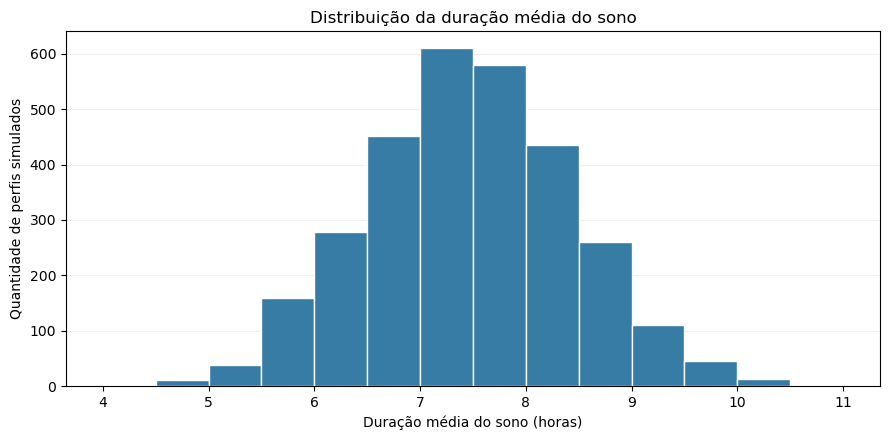

In [40]:
# Limites de meia em meia hora, de 4 a 11 horas.
limites_sono = [meia_hora / 2 for meia_hora in range(8, 23)]

fig, ax = plt.subplots(figsize=(9, 4.5))

ax.hist(
    dados["duracao_media_sono_horas"],
    bins=limites_sono,
    color="#377CA5",
    edgecolor="white"
)

ax.set_title("Distribuição da duração média do sono")
ax.set_xlabel("Duração média do sono (horas)")
ax.set_ylabel("Quantidade de perfis simulados")
ax.set_xticks(range(4, 12))
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()

A barra mais alta corresponde ao intervalo de 7,0 a menos de 7,5 horas de sono, com 610 perfis. O intervalo seguinte, de 7,5 a menos de 8,0 horas, reúne outros 579. Juntos, esses dois intervalos concentram 1.189 dos 3.000 perfis (39,63%). O histograma permite, assim, localizar com maior precisão a concentração observada anteriormente: dentro da faixa mais ampla de 6 a menos de 8 horas, as barras mais altas estão entre 7 e 8 horas.

Os valores observados variam de 4,4 a 10,9 horas. Essa amplitude ajuda a interpretar a média geral de 7,41 horas: embora ela descreva o centro do conjunto, há perfis com durações bastante distintas. As faixas utilizadas aqui descrevem a distribuição dos dados simulados; a adequação da duração do sono de uma pessoa exigiria considerar, entre outros fatores, sua idade.

### 6.2 Quais escores de estresse aparecem com maior frequência?

O nível de estresse foi registrado por meio de pontuações inteiras de 1 a 10. Para visualizar sua distribuição, utilizaremos um gráfico de barras com uma posição para cada escore, mantendo a ordem da escala. A altura de cada barra representa o percentual dos 3.000 perfis que receberam aquela pontuação.

Essa distribuição servirá de referência para a segunda pergunta de investigação. Nesta etapa, o percentual é calculado sobre a base completa. Quando compararmos as faixas de sono, o percentual será calculado dentro de cada faixa, pois os grupos têm tamanhos diferentes.

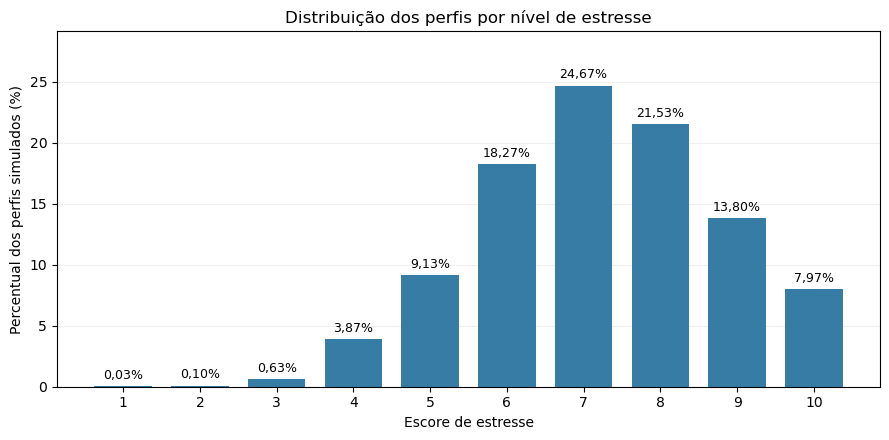

In [42]:
# Reutiliza a tabela de frequências calculada no Passo 3.
percentuais_estresse = frequencia_estresse["percentual"].sort_index()

fig, ax = plt.subplots(figsize=(9, 4.5))

barras = ax.bar(
    percentuais_estresse.index,
    percentuais_estresse.values,
    color="#377CA5",
    width=0.75
)

# Duas casas decimais permitem visualizar até os escores mais raros.
rotulos = [
    f"{percentual:.2f}%".replace(".", ",")
    for percentual in percentuais_estresse
]
ax.bar_label(barras, labels=rotulos, padding=3, fontsize=9)

ax.set_title("Distribuição dos perfis por nível de estresse")
ax.set_xlabel("Escore de estresse")
ax.set_ylabel("Percentual dos perfis simulados (%)")
ax.set_xticks(range(1, 11))
ax.set_ylim(0, percentuais_estresse.max() * 1.18)
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()

O escore 7 é o mais frequente, com 740 perfis (24,67%), seguido pelo escore 8, com 646 perfis (21,53%). Juntas, essas duas pontuações representam 46,2% da base. Na outra extremidade da distribuição, apenas um perfil recebeu escore 1 e três receberam escore 2.

Essa concentração é importante para interpretar as comparações seguintes. Encontrar muitos perfis com escores 7 ou 8 em determinada faixa de sono pode refletir uma característica que já está presente no conjunto completo. Por isso, a comparação entre as faixas deverá considerar a distribuição de todas as pontuações e o percentual que cada uma representa dentro do respectivo grupo.

Como os registros foram gerados por simulação, esses percentuais descrevem a composição da base utilizada no projeto. Eles não representam estimativas de prevalência de estresse entre estudantes reais.

## 7. Associação entre tempo de tela e duração média do sono

### 7.1 Pergunta de investigação

Qual é a direção e a intensidade da associação entre o tempo de tela e a duração média do sono nos perfis simulados?

No conjunto analisado, a média do tempo de tela foi de 6,49 horas, e a média da duração do sono foi de 7,41 horas. Essas duas informações, isoladamente, ainda deixam uma questão em aberto: os perfis com mais horas de tela também tendem a apresentar mais ou menos horas de sono? Para responder, precisamos examinar as duas medidas em conjunto, preservando o par de valores de cada perfil.

Escolhemos o gráfico de dispersão porque as duas variáveis são quantitativas. No eixo horizontal, representaremos o tempo de tela e, no eixo vertical, a duração média do sono. A correlação de Spearman complementará a leitura visual ao resumir em um coeficiente a direção e a intensidade da tendência observada. Sua escolha é adequada porque a pergunta envolve a ordenação dos perfis — se valores maiores de uma medida tendem a acompanhar valores menores ou maiores da outra — sem exigir que a relação siga uma reta.

In [43]:
resultado_tela_sono = calcular_correlacao_spearman(
    dados,
    "tempo_tela_horas",
    "duracao_media_sono_horas"
)

rho = resultado_tela_sono["rho_spearman"]
n_pares = resultado_tela_sono["pares_validos"]

print(f"Quantidade de perfis analisados: {n_pares}")
print(f"Coeficiente de Spearman: {rho:.3f}".replace(".", ","))

Quantidade de perfis analisados: 3000
Coeficiente de Spearman: -0,572


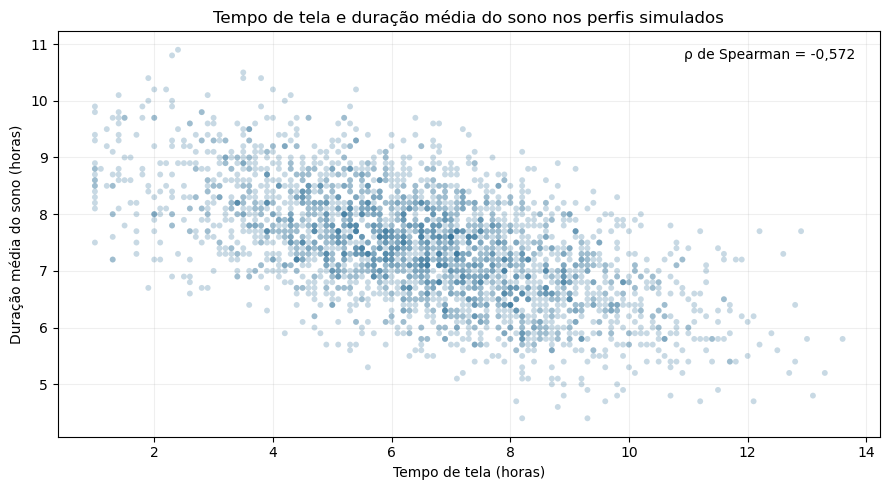

In [44]:
fig, ax = plt.subplots(figsize=(9, 5))

ax.scatter(
    dados["tempo_tela_horas"],
    dados["duracao_media_sono_horas"],
    s=18,
    alpha=0.25,
    color="#276B94",
    edgecolors="none"
)

ax.set_title("Tempo de tela e duração média do sono nos perfis simulados")
ax.set_xlabel("Tempo de tela (horas)")
ax.set_ylabel("Duração média do sono (horas)")
ax.set_axisbelow(True)
ax.grid(alpha=0.2)

texto_resumo = f"ρ de Spearman = {rho:.3f}".replace(".", ",")
ax.text(
    0.97, 0.96, texto_resumo,
    transform=ax.transAxes,
    ha="right", va="top"
)

fig.tight_layout()
plt.show()

In [45]:
# 6,5 horas corresponde à mediana do tempo de tela observada no Passo 3.
sono_com_6h30_de_tela = dados.loc[
    dados["tempo_tela_horas"] == 6.5,
    "duracao_media_sono_horas"
]

print("Perfis com 6,5 horas de tela:", sono_com_6h30_de_tela.count())
print("Menor duração do sono (h):", sono_com_6h30_de_tela.min())
print("Maior duração do sono (h):", sono_com_6h30_de_tela.max())

Perfis com 6,5 horas de tela: 62
Menor duração do sono (h): 5.6
Maior duração do sono (h): 9.2


### 7.2 Interpretação dos resultados

Nos 3.000 perfis simulados, observamos uma associação negativa entre o tempo de tela e a duração média do sono (ρ de Spearman = −0,572). No gráfico, essa associação aparece na tendência descendente da nuvem de pontos: à medida que avançamos para valores maiores de tempo de tela, tornam-se mais frequentes os perfis com menor duração de sono. A magnitude do coeficiente indica uma associação de intensidade moderada neste conjunto.

A dispersão dos pontos também revela diferenças importantes entre os perfis. Entre os 62 que registram exatamente 6,5 horas de tela, por exemplo, a duração do sono varia de 5,6 a 9,2 horas. Portanto, conhecer o tempo de tela ajuda a descrever uma tendência do grupo, mas é insuficiente para determinar quantas horas de sono um perfil apresenta.

O sentido da associação é coerente com a descrição da base, cuja geração incorporou uma relação entre maior tempo de tela e menor duração do sono. A contribuição da análise foi quantificar essa tendência e mostrar a variação que permanece entre perfis com o mesmo tempo de tela. Esses dados simulados não permitem concluir que reduzir o tempo de tela produziria uma mudança específica na duração do sono de estudantes reais.

## 8. Distribuição do estresse por faixa de duração do sono

Na análise da base completa, observamos que 46,2% dos perfis simulados receberam escore de estresse 7 ou 8. Esse resultado despertou uma segunda pergunta: a concentração dos escores é semelhante entre os perfis que dormem menos de 6 horas, de 6 a menos de 8 horas e 8 horas ou mais?

Para responder, vamos comparar as distribuições utilizando um boxplot. Em cada faixa, a linha dentro da caixa indica a mediana, e os limites da caixa correspondem aos percentis 25 e 75. Assim, podemos observar onde se concentra a metade central dos escores e verificar em que medida esses intervalos se sobrepõem.

Como as faixas possuem quantidades diferentes de perfis, também examinaremos a frequência de cada pontuação em relação ao total do próprio grupo. Essa informação complementa o gráfico, especialmente porque o estresse foi registrado em uma escala com apenas dez valores possíveis.

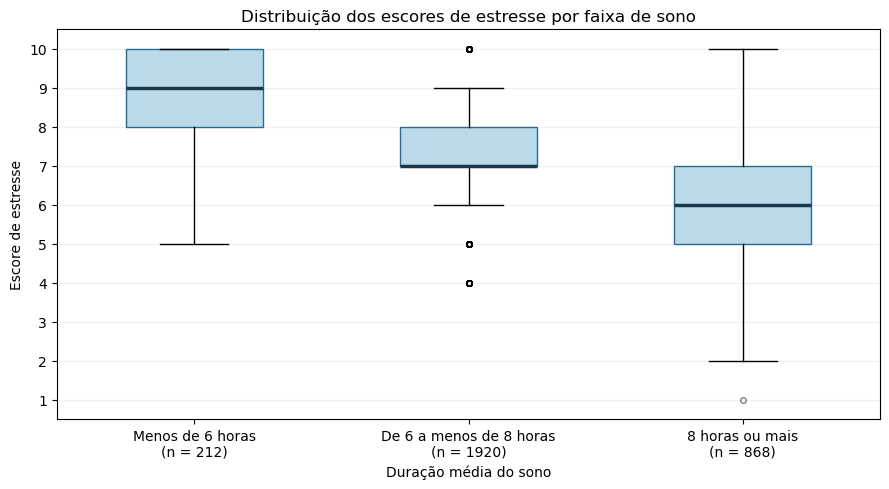

In [46]:
# Recupera as faixas na ordem definida no Passo 4.
faixas = dados["faixa_sono"].cat.categories

escores_por_faixa = [
    dados.loc[dados["faixa_sono"] == faixa, "nivel_estresse"].dropna()
    for faixa in faixas
]

# Inclui o tamanho de cada grupo no rótulo do eixo horizontal.
rotulos = [
    f"{faixa}\n(n = {len(escores)})"
    for faixa, escores in zip(faixas, escores_por_faixa)
]

fig, ax = plt.subplots(figsize=(9, 5))

ax.boxplot(
    escores_por_faixa,
    widths=0.5,
    patch_artist=True,
    boxprops={"facecolor": "#BBD9E8", "edgecolor": "#276B94"},
    medianprops={"color": "#17384D", "linewidth": 2.5},
    flierprops={"marker": "o", "markersize": 4, "alpha": 0.5}
)

ax.set_xticks(range(1, len(faixas) + 1), labels=rotulos)
ax.set_yticks(range(1, 11))
ax.set_ylim(0.5, 10.5)
ax.set_xlabel("Duração média do sono")
ax.set_ylabel("Escore de estresse")
ax.set_title("Distribuição dos escores de estresse por faixa de sono")
ax.set_axisbelow(True)
ax.grid(axis="y", alpha=0.2)

fig.tight_layout()
plt.show()

In [49]:
distribuicao_estresse = resumir_estresse_por_faixa_sono(dados)

percentuais_por_faixa = distribuicao_estresse.pivot(
    index="nivel_estresse",
    columns="faixa_sono",
    values="percentual_na_faixa"
)

display(percentuais_por_faixa.round(2).rename_axis(columns="Faixa de sono (%)"))

Faixa de sono (%),Menos de 6 horas,De 6 a menos de 8 horas,8 horas ou mais
nivel_estresse,,,
1,0.00,0.00,0.12
2,0.00,0.00,0.35
3,0.00,0.00,2.19
4,0.00,1.93,9.10
5,1.42,6.88,16.01
6,6.13,15.16,28.11
7,8.02,27.14,23.27
8,24.53,24.84,13.48
9,29.72,15.68,5.76


In [48]:
resultado_sono_estresse = calcular_correlacao_spearman(
    dados,
    "duracao_media_sono_horas",
    "nivel_estresse"
)

display(resultado_sono_estresse.to_frame(name="resultado"))

,resultado
variavel_x,duracao_media_sono_horas
variavel_y,nivel_estresse
pares_validos,3000
rho_spearman,-0.478


### 8.1 Interpretação dos resultados

Os escores de estresse tendem a ser menores nas faixas de maior duração média do sono. Entre os 212 perfis que dormem menos de 6 horas, a mediana foi 9, e a metade central dos escores ficou entre 8 e 10. Na faixa de 6 a menos de 8 horas, com 1.920 perfis, a mediana foi 7, e a metade central ficou entre 7 e 8. Entre os 868 perfis com 8 horas ou mais, a mediana foi 6, com a metade central entre 5 e 7.

Embora as medianas sejam diferentes, há sobreposição entre as distribuições. Os escores de 5 a 10 aparecem nas três faixas. O que muda é a frequência com que ocorrem: o escore 10, por exemplo, aparece em 30,19% dos perfis com menos de 6 horas de sono e em 1,61% dos perfis com 8 horas ou mais. Portanto, dois perfis de faixas distintas podem apresentar a mesma pontuação, mesmo quando o padrão predominante em seus grupos é diferente.

A correlação de Spearman calculada com as horas originais de sono foi de −0,478. O sinal negativo acompanha o padrão observado no boxplot: na base analisada, perfis com maior duração de sono tendem a apresentar escores menores de estresse. Como os dados foram simulados com relações planejadas entre as variáveis, essa associação descreve o comportamento do conjunto e não permite concluir que aumentar as horas de sono causaria uma redução do estresse em estudantes reais.

## 9. Conclusões e limitações

Este projeto investigou como o tempo de tela, a duração média do sono e o nível de estresse se relacionam em 3.000 perfis estudantis simulados.

Em relação à primeira pergunta, os perfis com mais horas de tela tenderam a apresentar menor duração média do sono. A correlação de Spearman foi de −0,572, indicando uma associação negativa de intensidade moderada. O gráfico de dispersão mostrou, porém, que há diferenças importantes entre perfis com o mesmo tempo de tela. Entre os 62 perfis com exatamente 6,5 horas de tela, a duração média do sono variou de 5,6 a 9,2 horas. Assim, o tempo de tela ajuda a descrever uma tendência do conjunto, mas oferece informação limitada sobre a duração do sono de um perfil específico.

Quanto à segunda pergunta, a mediana do escore de estresse foi 9 entre os perfis com menos de 6 horas de sono, 7 entre aqueles com 6 a menos de 8 horas e 6 entre os que apresentaram 8 horas ou mais. Apesar dessa diferença, os escores de 5 a 10 ocorreram nas três faixas. A frequência dessas pontuações ajuda a compreender a sobreposição: o escore 10, por exemplo, apareceu em 30,19% dos perfis da faixa de menor duração do sono e em 1,61% dos perfis da faixa de maior duração. Quando utilizamos as horas de sono originais, a correlação de Spearman de −0,478 também indicou que maiores durações de sono tendem a acompanhar menores escores de estresse.

### 9.1 Limitações e alcance dos resultados

A principal limitação decorre da origem da base. Os perfis foram gerados para fins educacionais, com relações estatísticas planejadas entre algumas variáveis. Os coeficientes e percentuais obtidos descrevem a intensidade e a variação desses padrões na simulação. Investigar se relações semelhantes ocorrem entre estudantes reais exigiria dados coletados nessa população. Também seria inadequado usar esses resultados para estimar quanto o sono de uma pessoa mudaria ao reduzir seu tempo de tela.

A escolha das faixas de sono também influencia a leitura das comparações. Por exemplo, perfis com 7,9 e 8,0 horas ficam em grupos diferentes, embora suas durações sejam muito próximas. Por isso, os cortes de 6 e 8 horas foram adotados como critérios descritivos, e a análise por grupos foi complementada pela correlação calculada com as horas originais.

Durante a preparação, o tempo de redes sociais foi limitado ao tempo total de tela em 42 perfis, sob a premissa de que as duas medidas se referem ao mesmo período. Essa decisão foi documentada e os valores originais foram preservados. Como as duas investigações utilizaram o tempo total de tela, a duração do sono e o escore de estresse, o tratamento aplicado à variável de redes sociais não alterou os resultados apresentados.